## Question 1

In [75]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [76]:
# Load image
im = cv.imread(r"C:\Users\USER\Desktop\UNI\Semesters\Semester 5\Machine_Vision\New folder\Image-Processing-and-Machine-Vision-Assignment_02\a2images\the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

# Get grayscale image
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

In [77]:
# Select range of sigma
sigma_values = np.linspace(1, 2, 3)
# Threhsold for blob detection
threshold = 0.35

# Store responses of each scale
blob_responses = []

for sigma in sigma_values:
    print(f"Processing scale with sigma = {sigma}")

    # Apply Gaussian blur
    gaussian_blur = cv.GaussianBlur(gray, (0, 0), sigma)
    # Compute Laplacian of Gaussian (LoG)
    laplacian = cv.Laplacian(gaussian_blur, cv.CV_64F)

    # Get absolute value
    blob_response = sigma**2 * np.abs(laplacian)

    # Threshold the response and get contours
    mask = blob_response > threshold * blob_response.max()
    contours, _ = cv.findContours(mask.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # Draw contours as circles
    for contour in contours:
        if len(contour) >= 5:
            # Get the center and radius of the enclosing circle from contour
            (center_x, center_y), radius = cv.minEnclosingCircle(contour)
            # Convert to integers
            center = (int(center_x), int(center_y))
            radius = int(radius)
            blob_responses.append((center, radius, sigma))

Processing scale with sigma = 1.0
Processing scale with sigma = 1.5
Processing scale with sigma = 2.0


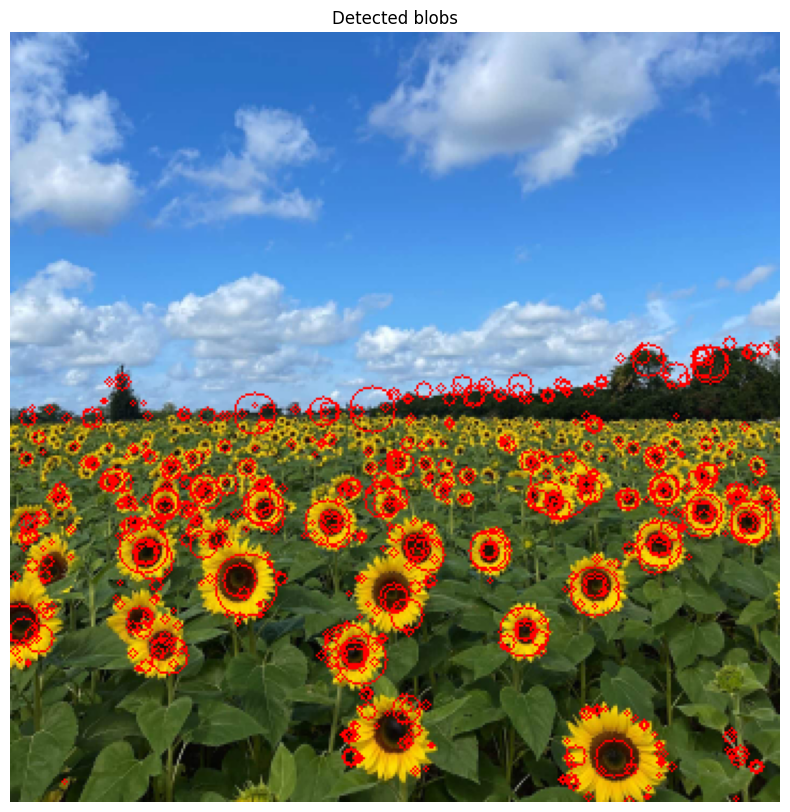

In [78]:
# Draw all detected circles with the specified line thickness
#output = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

output = im.copy()
for blob in blob_responses:
    center, radius, _ = blob
    cv.circle(output, center, radius, (0,0,255), 1)

# Display the grayscale image with detected circles
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB), cmap='gray')
plt.axis('off')
plt.title('Detected blobs')
plt.show()

## Question 2

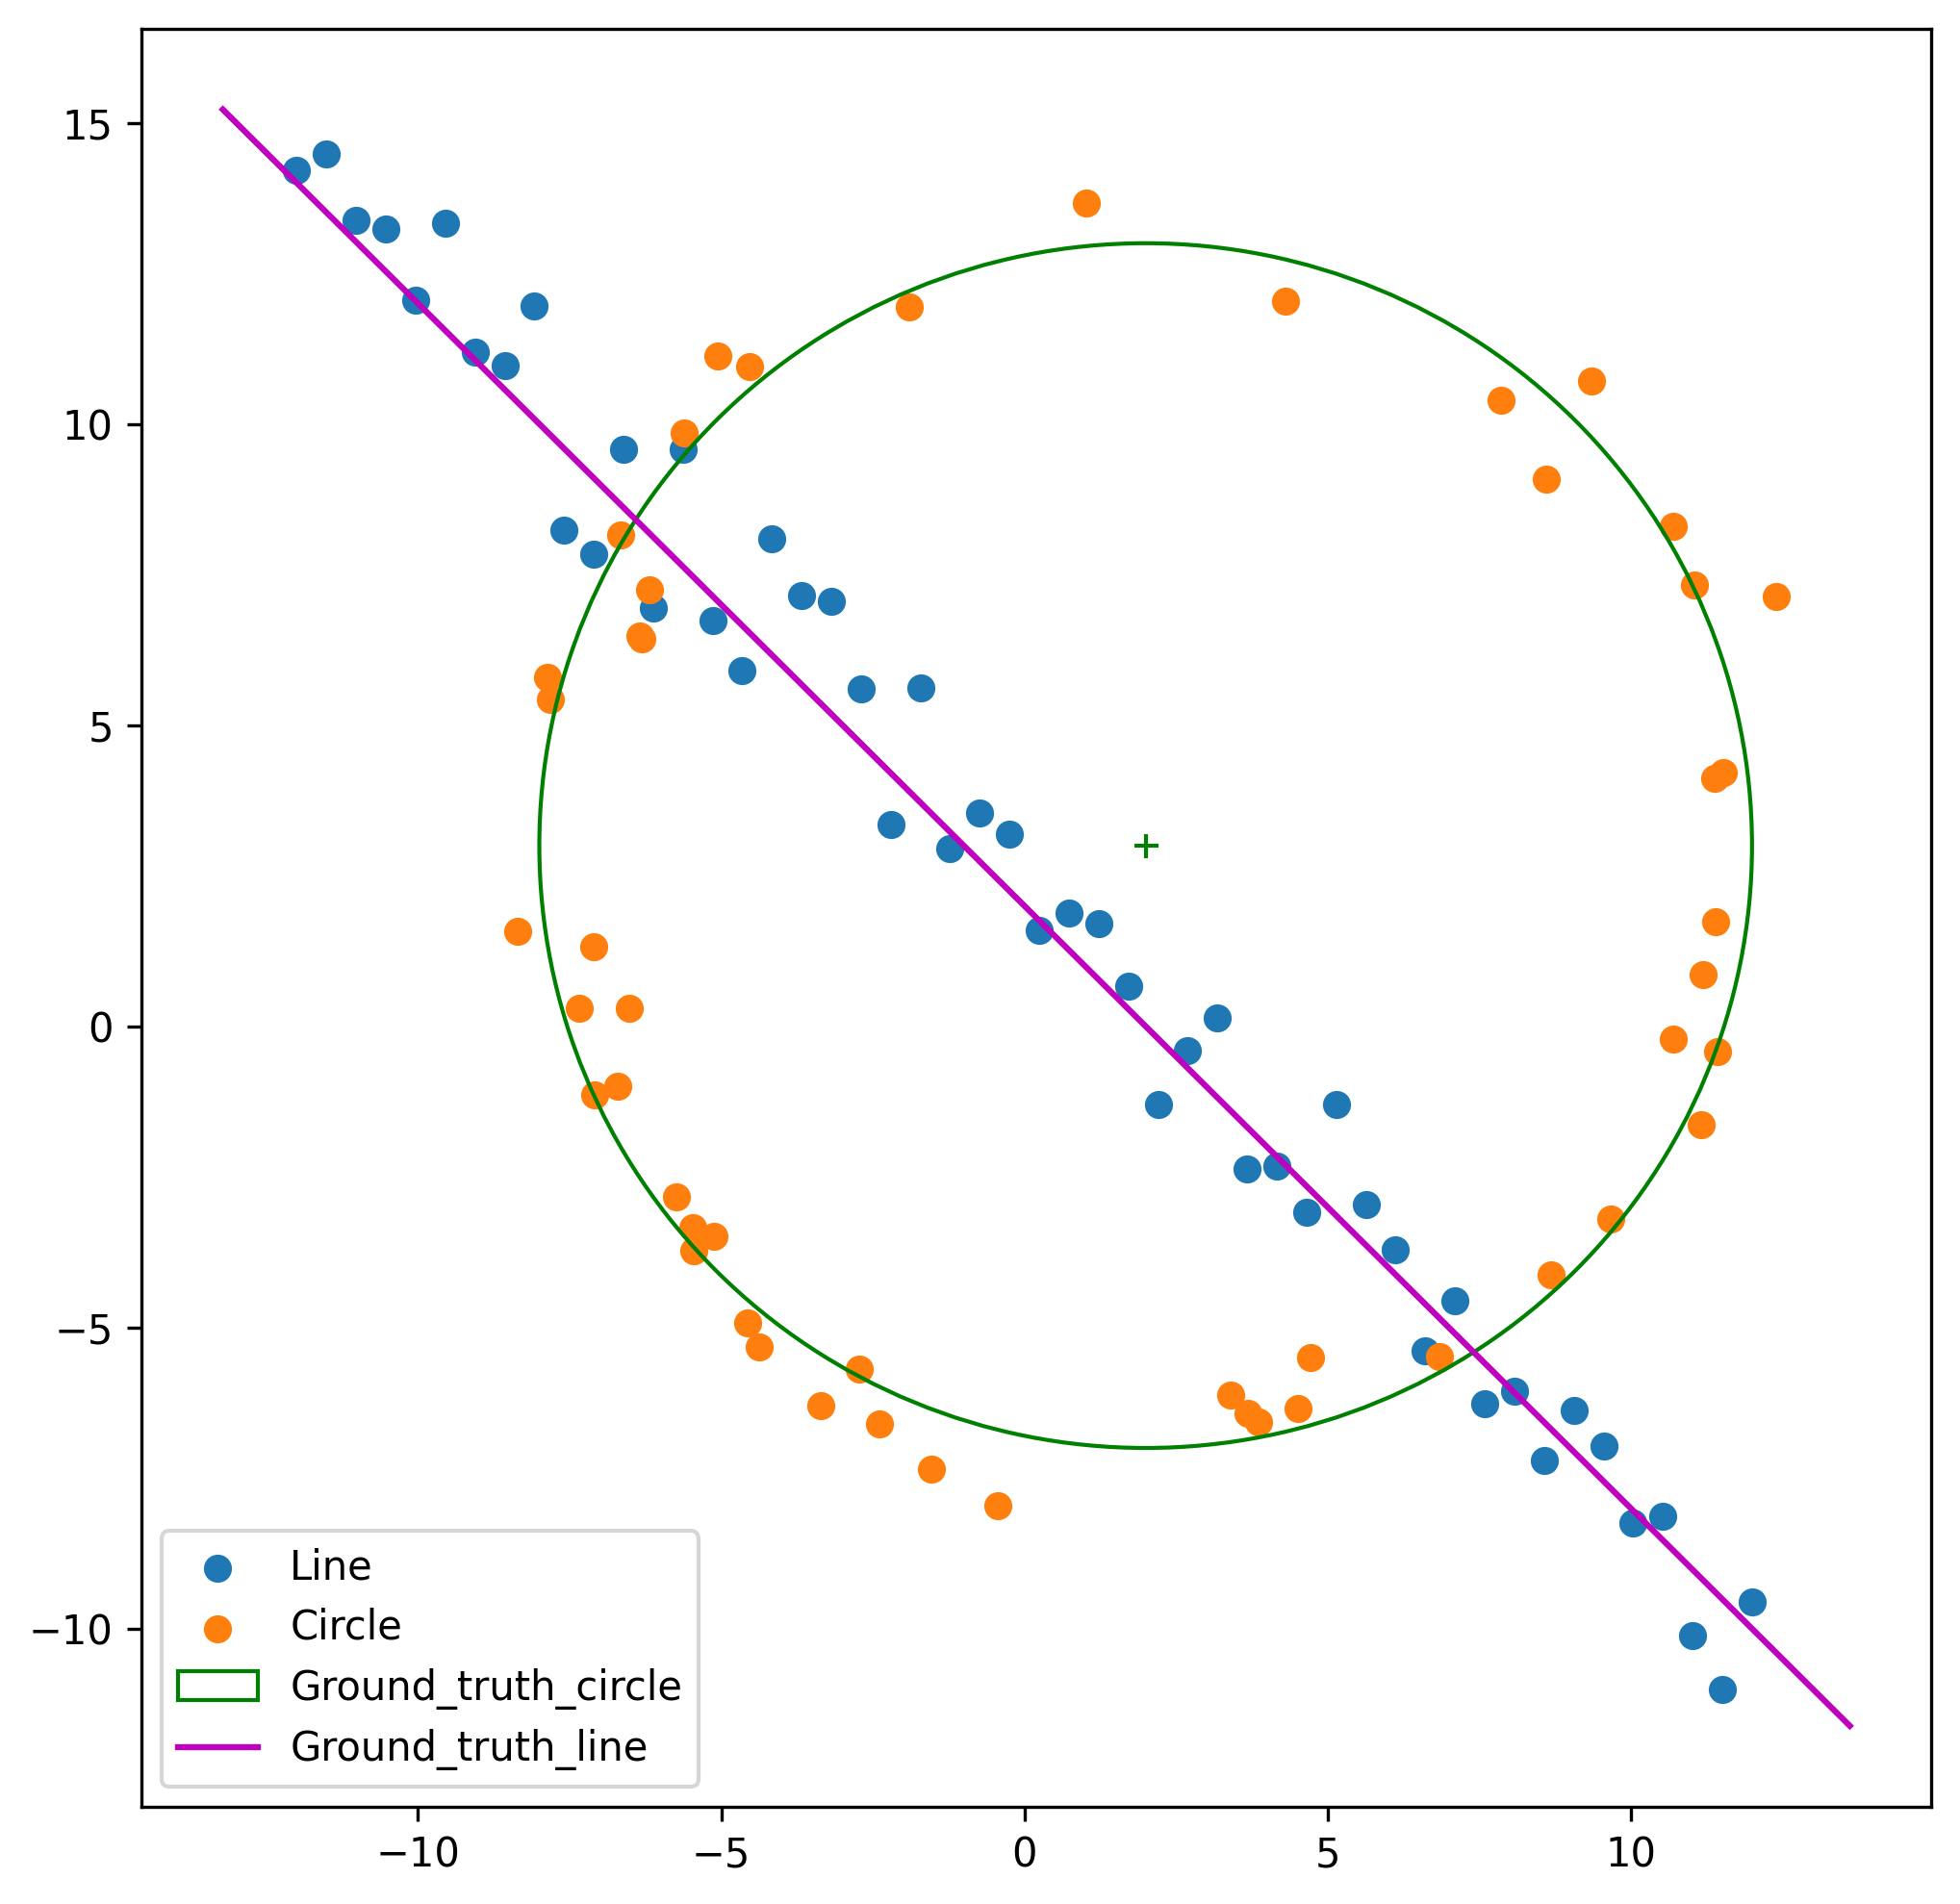

In [80]:
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)
N = 100
half_n = N//2

r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
X = np.vstack((X_circ, X_line))  # All points

fig, ax = plt.subplots(1,1, figsize=(8,8), dpi=300)
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1], label='Circle')
circle_gt = plt.Circle((x0_gt,y0_gt), r, color='g', fill=False, label='Ground_truth_circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground_truth_line')
plt.legend()

# 1.Line using RANSAC

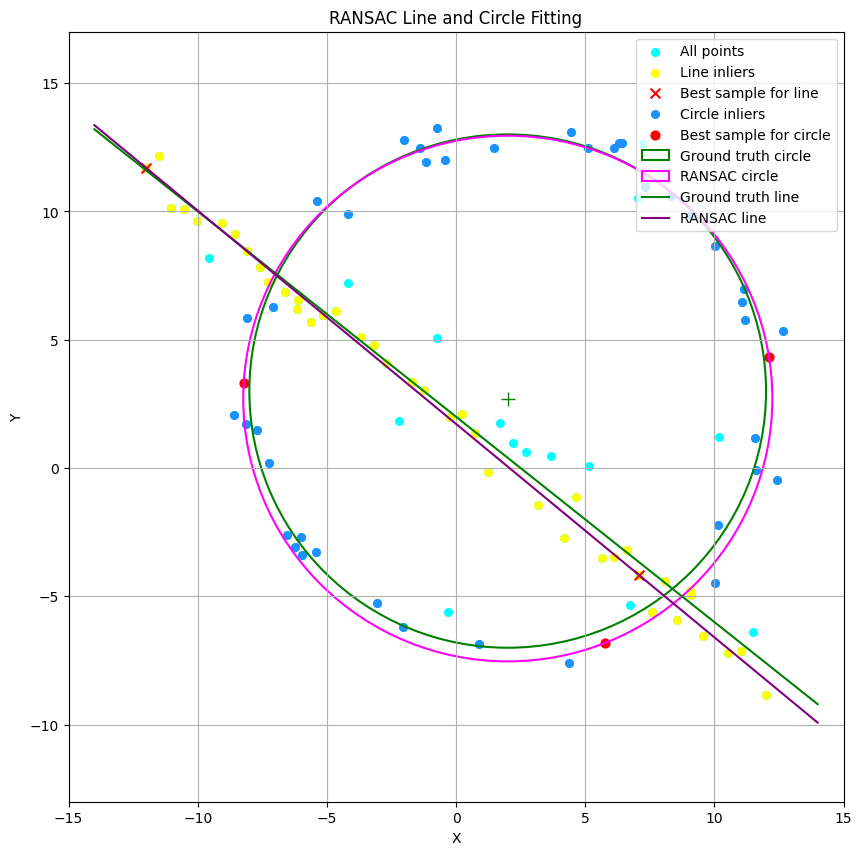

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- 0. Data Generation (Listing 1 from Assignment) ---
np.random.seed(42)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Circle Center
s_circ = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n_noise = s_circ * np.random.randn(half_n)
x_c = x0_gt + (r + n_noise) * np.cos(t)
y_c = y0_gt + (r + n_noise) * np.sin(t)
X_circ = np.hstack((x_c.reshape(half_n, 1), y_c.reshape(half_n, 1)))

m_gt, b_gt = -0.8, 2
s_line = 1.0
x_l = np.linspace(-12, 12, half_n)
y_l = m_gt * x_l + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_l.reshape(half_n, 1), y_l.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))  # All points

# --- Part (a): RANSAC Line Fitting ---
def fit_line_model(p1, p2):
    # Returns normal [a, b] and distance d
    v = p2 - p1
    normal = np.array([-v[1], v[0]])
    norm_val = np.linalg.norm(normal)
    if norm_val == 0:
        return 0, 0, 0
    normal = normal / norm_val
    d = np.dot(normal, p1)
    if d < 0:  # Ensure consistent sign
        normal = -normal
        d = -d
    return normal[0], normal[1], d

def ransac_line(points, iterations=1000, threshold=0.8):
    best_inliers = []
    best_params = None
    best_sample = None
    
    for _ in range(iterations):
        sample_idx = np.random.choice(len(points), 2, replace=False)
        p1, p2 = points[sample_idx[0]], points[sample_idx[1]]
        
        a, b, d = fit_line_model(p1, p2)
        if a == 0 and b == 0:
            continue
            
        # Compute perpendicular distances: |ax + by - d|
        distances = np.abs(np.dot(points, np.array([a, b])) - d)
        inliers = np.where(distances < threshold)[0]
        
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
            best_params = (a, b, d)
            best_sample = (p1, p2)
            
    return best_params, best_inliers, best_sample

line_params, line_inlier_indices, line_sample = ransac_line(X)
a, b, d = line_params
X_line_inliers = X[line_inlier_indices]

# Remove line inliers to get remnant points for circle fitting
mask = np.ones(len(X), dtype=bool)
mask[line_inlier_indices] = False
X_remnant = X[mask]

# --- Part (b): RANSAC Circle Fitting ---
def fit_circle_algebraic(p1, p2, p3):
    # Fit circle through 3 points
    A = np.array([
        [2 * p1[0], 2 * p1[1], 1],
        [2 * p2[0], 2 * p2[1], 1],
        [2 * p3[0], 2 * p3[1], 1]
    ])
    Y = np.array([
        p1[0]**2 + p1[1]**2,
        p2[0]**2 + p2[1]**2,
        p3[0]**2 + p3[1]**2
    ])
    try:
        sol = np.linalg.solve(A, Y)
        xc, yc = sol[0], sol[1]
        r = np.sqrt(sol[2] + xc**2 + yc**2)
        return xc, yc, r
    except:
        return 0, 0, 0

def ransac_circle(points, iterations=2000, threshold=0.8):
    best_inliers = []
    best_params = None
    best_sample = None
    
    for _ in range(iterations):
        if len(points) < 3:
            break
        sample_idx = np.random.choice(len(points), 3, replace=False)
        p1, p2, p3 = points[sample_idx[0]], points[sample_idx[1]], points[sample_idx[2]]
        
        xc, yc, r = fit_circle_algebraic(p1, p2, p3)
        if r <= 0 or r > 50:
            continue
            
        # Compute radial errors: |sqrt((x-xc)^2 + (y-yc)^2) - r|
        distances = np.abs(np.sqrt((points[:, 0] - xc)**2 + (points[:, 1] - yc)**2) - r)
        inliers = np.where(distances < threshold)[0]
        
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
            best_params = (xc, yc, r)
            best_sample = (p1, p2, p3)
            
    return best_params, best_inliers, best_sample

circle_params, circle_inlier_indices_remnant, circle_sample = ransac_circle(X_remnant)
xc, yc, r_fit = circle_params

# Map remnant inlier indices back to original X indices
remnant_indices = np.where(mask)[0]
circle_inlier_indices = remnant_indices[circle_inlier_indices_remnant]
X_circle_inliers = X[circle_inlier_indices]

# --- Part (c): Comprehensive Plotting (Figure 1 Style) ---
fig, ax = plt.subplots(figsize=(10, 10))

# 1. All points
ax.scatter(X[:, 0], X[:, 1], color='cyan', label='All points', s=30)
# 2. Line inliers
ax.scatter(X_line_inliers[:, 0], X_line_inliers[:, 1], color='yellow', label='Line inliers', s=30)
# 3. Best sample for line
ax.scatter(line_sample[0][0], line_sample[0][1], color='red', marker='x', s=50, label='Best sample for line')
ax.scatter(line_sample[1][0], line_sample[1][1], color='red', marker='x', s=50)

# 4. Circle inliers
ax.scatter(X_circle_inliers[:, 0], X_circle_inliers[:, 1], color='dodgerblue', label='Circle inliers', s=30)
# 5. Best sample for circle
ax.scatter(circle_sample[0][0], circle_sample[0][1], color='red', marker='o', s=40, label='Best sample for circle')
ax.scatter(circle_sample[1][0], circle_sample[1][1], color='red', marker='o', s=40)
ax.scatter(circle_sample[2][0], circle_sample[2][1], color='red', marker='o', s=40)

# 6. Ground truth circle & RANSAC circle
gt_circle = plt.Circle((x0_gt, y0_gt), r, color='green', fill=False, linewidth=1.5, label='Ground truth circle')
ransac_circle_patch = plt.Circle((xc, yc), r_fit, color='magenta', fill=False, linewidth=1.5, label='RANSAC circle')
ax.add_patch(gt_circle)
ax.add_patch(ransac_circle_patch)
ax.plot(xc, yc, '+', color='green', markersize=10)

# 7. Ground truth line & RANSAC line
x_vals = np.array([-14, 14])
y_gt_vals = m_gt * x_vals + b_gt
ax.plot(x_vals, y_gt_vals, color='green', linewidth=1.5, label='Ground truth line')

# RANSAC line plot: ax + by = d => y = (d - ax)/b
y_ransac_vals = (d - a * x_vals) / b
ax.plot(x_vals, y_ransac_vals, color='purple', linewidth=1.5, label='RANSAC line')

ax.set_xlim(-15, 15)
ax.set_ylim(-13, 17)
ax.legend(loc='upper right')
plt.title("RANSAC Line and Circle Fitting")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()